# 04. Modélisation Machine Learning — Prédiction de la Vulnérabilité Multisectorielle Aiguë

Ce notebook répond à la problématique centrale du projet d'évaluation humanitaire :

> **« Comment identifier et prédire le niveau de vulnérabilité critique des ménages à partir de leurs caractéristiques socio-démographiques pour optimiser le ciblage de l'aide humanitaire ? »**

---

### Cadrage méthodologique et opérationnel :
1. **Source de vérité : La base relationnelle SQLite (`outputs/enquete_ms.db`)**
   - Plutôt que d'utiliser un export CSV figé, les données sont extraites directement de la **base de données relationnelle SQLite** via une jointure complète (`JOIN`) des tables thématiques (`MENAGE`, `COMPOSITION_MENAGE`, `VULNERABILITE_SANTE`, etc.).
   - Cela garantit que toute correction ou suppression réalisée en amont dans l'application est fidèlement prise en compte.
2. **Construction de la cible ($Y$) et absence de scores préexistants :**
   - Les scores sectoriels ne sont pas stockés en dur dans la base SQL : ils sont calculés dynamiquement à l'aide du moteur métier validé `src.tech_scores.calculer_scores`.
   - La cible binaire **$Y$ (Vulnérabilité Multisectorielle Aiguë)** est construite selon le cadre **JIAF 2.0** : un ménage est prioritaire s'il cumule au moins **3 sévérités sectorielles critiques** (Sécurité alimentaire, Eau/WASH, Biens essentiels AME, Moyens d'existence agricoles).
3. **Prévention stricte du Data Leakage (Fuite de données) :**
   - **Toutes les questions sectorielles techniques** ayant servi à calculer les scores ($Y$) sont **strictement bannies des prédicteurs ($X$)**.
   - Le jeu $X$ repose **exclusivement sur les données socio-démographiques** : statut du ménage (réfugié, déplacé, autochtone hôte), composition familiale par âge et genre, profil du chef de ménage, et vulnérabilités transversales de santé/handicap.
4. **Comparaison de 2 modèles avec GridSearch :**
   - **Modèle 1 (Linéaire & interprétable) :** Régression Logistique pénalisée (Baseline « boîte blanche »).
   - **Modèle 2 (Ensembliste & non-linéaire) :** Forêt Aléatoire (*Random Forest Classifier*).
   - Métrique directrice : **Rappel (Recall)** et **$F_2$-Score**, car l'erreur critique en contexte humanitaire est le **Faux Négatif** (exclure un ménage en détresse vitale).
5. **Sauvegarde du modèle et distinction Entraînement vs Inférence :**
   - Le modèle optimal est exporté avec `joblib` dans `outputs/ml/modele_vulnerabilite.joblib`.
   - **Règle de sécurité MLOps pour le terrain :** Le réentraînement par GridSearch est un processus lourd et sensible (contrôle des biais et éthique) réservé au Data Scientist. Les agents non-techniques sur Streamlit n'ont accès qu'au **mode Inférence (Prédiction instantanée)**.


## 1. Environnement et bibliothèques


In [1]:
import os
import sys
import sqlite3
from contextlib import closing
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    fbeta_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Configuration graphique
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

# Positionnement à la racine du projet
RACINE_PROJET = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(RACINE_PROJET) not in sys.path:
    sys.path.insert(0, str(RACINE_PROJET))

from src.tech_scores import calculer_scores
print("Environnement initialisé avec succès.")


Environnement initialisé avec succès.


## 2. Extraction depuis la base SQLite (`outputs/enquete_ms.db`) & Calcul des scores sectoriels

### Pourquoi partir de la base de données relationnelle ?
1. **Source de vérité :** La base SQLite consolide l'état le plus à jour des enquêtes après les étapes de nettoyage et d'ingestion.
2. **Reconstitution par jointure SQL :** Les différentes dimensions du questionnaire (composition, santé, eau, alimentation, agriculture) sont jointes par `id_menage`.
3. **Calcul dynamique des scores :** Les scores sectoriels n'étant pas stockés en dur dans SQLite, la fonction validée `calculer_scores(df_sql)` génère à la volée l'ensemble des indicateurs humanitaires nécessaires à la définition de la cible.


In [2]:
chemin_base_sql = RACINE_PROJET / "outputs" / "enquete_ms.db"
chemin_csv_fallback = RACINE_PROJET / "outputs" / "donnees_nettoyees.csv"
if not chemin_csv_fallback.exists():
    chemin_csv_fallback = RACINE_PROJET / "outputs_demo" / "donnees_nettoyees.csv"

# Requête SQL pour extraire et joindre les tables relationnelles
requete_jointure = """
SELECT m.id_menage,
       me.date_enquete,
       m.age,
       m.sexe,
       m.statmtr, m.decision, m.status,
       sm.herber, sm.herber AS lieu_hab, sm.environ,
       sm.loyer_depl_montant, sm.loyer_auto_montant,
       cm.h_0_5, cm.h_6_24, cm.h_25_59, cm.h_5_14,
       cm.h_15_17, cm.h_18_49, cm.h_50_59, cm.h_plus60,
       cm.f_0_5, cm.f_6_24, cm.f_25_59, cm.f_5_14,
       cm.f_15_17, cm.f_18_49, cm.f_50_59, cm.f_plus60,
       cm.fem_enc, cm.fem_all,
       vs.vis_ss, vs.hear_ss, vs.mob_ss, vs.cog_ss, vs.sc_ss, vs.com_ss,
       vs.observation_0, vs.adultincap, vs.hand, vs.malnut,
       er.revenu, er.montant_dette,
       sa.ressources, sa.repas_r, sa.suffisant, sa.repas_f, sa.manque, sa.repas_m,
       ba.nb_bidon, ba.nb_cass, ba.nb_bas, ba.nb_outil,
       ba.nb_couch, ba.nb_couv, ba.nb_habit_femme, ba.nb_habit_e,
       we.capacite, we.capacites, we.eau, we.separer,
       ag.agro, ag.terre, ag.outims, ag.personne, ag.eau_point, ag.asso, ag.date_agro
FROM MENAGE m
INNER JOIN META_ENQUETE me ON me.id_menage = m.id_menage
LEFT JOIN STATUT_MENAGE sm ON sm.id_menage = m.id_menage
LEFT JOIN COMPOSITION_MENAGE cm ON cm.id_menage = m.id_menage
LEFT JOIN VULNERABILITE_SANTE vs ON vs.id_menage = m.id_menage
LEFT JOIN ECONOMIE_REVENU er ON er.id_menage = m.id_menage
LEFT JOIN SECURITE_ALIMENTAIRE sa ON sa.id_menage = m.id_menage
LEFT JOIN BIENS_AME ba ON ba.id_menage = m.id_menage
LEFT JOIN WASH_EAU we ON we.id_menage = m.id_menage
LEFT JOIN AGRICULTURE ag ON ag.id_menage = m.id_menage
"""

if chemin_base_sql.exists():
    print(f"Extraction depuis la base SQLite : {chemin_base_sql}")
    with closing(sqlite3.connect(chemin_base_sql)) as conn:
        df_brut = pd.read_sql_query(requete_jointure, conn)
else:
    print(f"Base SQLite introuvable, repli sur le fichier CSV : {chemin_csv_fallback}")
    df_brut = pd.read_csv(chemin_csv_fallback, low_memory=False)
    if "lieu_hab" not in df_brut.columns and "herber" in df_brut.columns:
        df_brut["lieu_hab"] = df_brut["herber"]

print(f"Données brutes chargées : {df_brut.shape[0]:,} ménages et {df_brut.shape[1]} colonnes.")

# Calcul à la volée de tous les scores sectoriels standardisés
df_scores = calculer_scores(df_brut)
print(f"Scores calculés avec succès : {df_scores.shape[1]} indicateurs disponibles.")


Extraction depuis la base SQLite : c:\Users\maril\Documents\Enquête Multisectorielle - ONG\outputs\enquete_ms.db
Données brutes chargées : 50,000 ménages et 67 colonnes.
Scores calculés avec succès : 134 indicateurs disponibles.


## 3. Construction de la cible ($Y$) : L'Index de Vulnérabilité Multisectorielle Aiguë

Dans l'approche **JIAF 2.0**, la vulnérabilité d'un ménage est définie par l'accumulation de chocs et de sévérités sectorielles critiques :
1. **Sécurité Alimentaire (HHS) :** Faim modérée à sévère ($HHS \ge 2$).
2. **Eau & Assainissement (WASH) :** Niveau 3 critique (recours à des eaux de surface ou sources non améliorées).
3. **Biens Essentiels (AME) :** Phase de crise / urgence matérielle sévère (score AME $\ge 4.0$).
4. **Moyens d'existence agricoles (AGRO) :** Précarité productive aiguë (score global AGRO $\ge 3$).

**Définition de la cible binaire :**
- **$Y = 1$ (Prioritaire / Vulnérabilité Aiguë) :** Cumul $\ge 3$ secteurs critiques.
- **$Y = 0$ (Non prioritaire dans l'urgence) :** Moins de 3 secteurs critiques.


In [3]:
# 1. Piliers sectoriels en sévérité critique
secal_critique = df_scores["score_hhs_total"].ge(2).fillna(False).astype(int)
wash_critique = df_scores["score_global_wash"].eq(3).fillna(False).astype(int)
ame_critique = df_scores["score_ame_global"].ge(4.0).fillna(False).astype(int)
agro_critique = df_scores["score_global_agro"].ge(3).fillna(False).astype(int)

# 2. Cumul multisectoriel
cumul_severites = secal_critique + wash_critique + ame_critique + agro_critique

# 3. Variable binaire cible
y = (cumul_severites >= 3).astype(int)

print("Distribution de la cible Y :")
repart = pd.Series(y).value_counts(normalize=True).rename({0: "Non prioritaire (0 à 2 crises)", 1: "Prioritaire (>= 3 crises)"})
for label, prop in repart.items():
    effectif = (y == (1 if 'Prioritaire' in label else 0)).sum()
    print(f" - {label} : {effectif:,} ménages ({prop*100:.2f}%)")


Distribution de la cible Y :
 - Non prioritaire (0 à 2 crises) : 31,506 ménages (63.01%)
 - Prioritaire (>= 3 crises) : 18,494 ménages (36.99%)


## 4. Sélection des prédicteurs ($X$) & Prévention absolue du Data Leakage

### Protocole anti-fuite de données :
Pour que le modèle réponde à la question de recherche (*« Les critères socio-démographiques suffisent-ils à cibler l'aide ? »*), **aucune question sectorielle n'est injectée dans $X$**.

Le vecteur $X$ utilise exclusivement :
- **Statut de déplacement :** `status` (réfugié, déplacé interne, autochtone hôte, autochtone non hôte).
- **Profil du chef de ménage :** `age`, `sexe`, `statmtr` (statut matrimonial).
- **Structure détaillée du foyer :** Répartition par genre et tranches d'âge (`h_0_5`, `f_0_5`, `h_5_14`, `f_5_14`, etc.).
- **Vulnérabilités transversales déclarées :** Femmes enceintes/allaitantes (`fem_enc`, `fem_all`), malnutrition (`malnut`), adultes dépendants (`adultincap`), handicap et limitations fonctionnelles du Washington Group (`hand`, `vis_ss`, `hear_ss`, `mob_ss`, etc.).


In [4]:
features_numeriques = [
    'age',
    'h_0_5', 'f_0_5', 'h_6_24', 'f_6_24', 'h_5_14', 'f_5_14',
    'h_15_17', 'f_15_17', 'h_18_49', 'f_18_49', 'h_50_59', 'f_50_59',
    'h_plus60', 'f_plus60',
    'adultincap'
]

features_categorielles = [
    'status', 'sexe', 'statmtr',
    'fem_enc', 'fem_all', 'hand', 'malnut',
    'vis_ss', 'hear_ss', 'mob_ss', 'cog_ss', 'sc_ss', 'com_ss'
]

X = df_brut[features_numeriques + features_categorielles].copy()
print(f"Matrice explicative X : {X.shape[0]:,} lignes, {X.shape[1]} variables socio-démographiques pures.")
print("Vérification : Zéro fuite de données (aucune variable sectorielle AME/WASH/SECAL/AGRO dans X).")


Matrice explicative X : 50,000 lignes, 29 variables socio-démographiques pures.
Vérification : Zéro fuite de données (aucune variable sectorielle AME/WASH/SECAL/AGRO dans X).


## 5. Découpage stratifié Train / Test et Pipeline de prétraitement

Le split (80% Train, 20% Test) est stratifié (`stratify=y`) pour préserver les proportions de ménages vulnérables.
Tout le prétraitement est encapsulé dans un `ColumnTransformer` scikit-learn :
- **Numériques :** Imputation médiane + mise à l'échelle standard (`StandardScaler`).
- **Catégorielles :** Imputation par une modalité explicite `'manquant'` + `OneHotEncoder(handle_unknown='ignore')`.


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Ensemble d'entraînement : {X_train.shape[0]:,} ménages")
print(f"Ensemble de test : {X_test.shape[0]:,} ménages")

transformateur_num = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

transformateur_cat = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='manquant')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocesseur = ColumnTransformer([
    ('num', transformateur_num, features_numeriques),
    ('cat', transformateur_cat, features_categorielles)
])

print("Pipeline de prétraitement configurée avec étanchéité statistique.")


Ensemble d'entraînement : 40,000 ménages
Ensemble de test : 10,000 ménages
Pipeline de prétraitement configurée avec étanchéité statistique.


## 6. Modèle 1 — Régression Logistique (Modèle linéaire de référence)

### Pourquoi ce modèle ?
Modèle de référence (« boîte blanche »), transparent et directement interprétable via ses coefficients.
Il est optimisé avec `GridSearchCV` (5-fold stratifié) en orientant le score vers le **Recall** (Rappel).


In [6]:
pipe_logreg = Pipeline([
    ('preprocesseur', preprocesseur),
    ('classifieur', LogisticRegression(max_iter=1000, random_state=42))
])

grille_logreg = {
    'classifieur__C': [0.01, 0.1, 1.0, 10.0],
    'classifieur__penalty': ['l1', 'l2'],
    'classifieur__solver': ['liblinear', 'saga'],
    'classifieur__class_weight': ['balanced', None]
}

cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_logreg = GridSearchCV(
    estimator=pipe_logreg,
    param_grid=grille_logreg,
    scoring='recall',
    cv=cv_strat,
    n_jobs=-1,
    verbose=1
)

print("Lancement du GridSearch pour la Régression Logistique...")
grid_logreg.fit(X_train, y_train)

meilleur_logreg = grid_logreg.best_estimator_
print("\nMeilleurs hyperparamètres (Régression Logistique) :")
for p, v in grid_logreg.best_params_.items():
    print(f" - {p.replace('classifieur__', '')} : {v}")
print(f"Rappel moyen en validation croisée : {grid_logreg.best_score_:.4f}")


Lancement du GridSearch pour la Régression Logistique...
Fitting 5 folds for each of 32 candidates, totalling 160 fits

Meilleurs hyperparamètres (Régression Logistique) :
 - C : 0.01
 - class_weight : balanced
 - penalty : l1
 - solver : saga
Rappel moyen en validation croisée : 0.6690


## 7. Modèle 2 — Forêt Aléatoire (*Random Forest Classifier*)

### Pourquoi ce modèle ?
Modèle ensembliste non-linéaire capable de capturer des interactions complexes (comme le comportement spécifique des autochtones familles d'accueil repéré dans l'EDA) sans exiger d'hypothèse de linéarité.


In [7]:
pipe_rf = Pipeline([
    ('preprocesseur', preprocesseur),
    ('classifieur', RandomForestClassifier(random_state=42))
])

grille_rf = {
    'classifieur__n_estimators': [100, 200],
    'classifieur__max_depth': [8, 12, 16],
    'classifieur__min_samples_split': [5, 15],
    'classifieur__class_weight': ['balanced', 'balanced_subsample']
}

grid_rf = GridSearchCV(
    estimator=pipe_rf,
    param_grid=grille_rf,
    scoring='recall',
    cv=cv_strat,
    n_jobs=-1,
    verbose=1
)

print("Lancement du GridSearch pour la Forêt Aléatoire...")
grid_rf.fit(X_train, y_train)

meilleur_rf = grid_rf.best_estimator_
print("\nMeilleurs hyperparamètres (Forêt Aléatoire) :")
for p, v in grid_rf.best_params_.items():
    print(f" - {p.replace('classifieur__', '')} : {v}")
print(f"Rappel moyen en validation croisée : {grid_rf.best_score_:.4f}")


Lancement du GridSearch pour la Forêt Aléatoire...
Fitting 5 folds for each of 24 candidates, totalling 120 fits

Meilleurs hyperparamètres (Forêt Aléatoire) :
 - class_weight : balanced
 - max_depth : 8
 - min_samples_split : 5
 - n_estimators : 200
Rappel moyen en validation croisée : 0.7319


Nous retenons la Forêt Aléatoire : grâce à sa capacité à croiser les critères socio-démographiques sans hypothèse de linéarité, elle fait passer le taux de détection des ménages critiques (Rappel) de 66,9 % à 73,2 % par rapport à la Régression Logistique. Avec une profondeur maîtrisée (max_depth = 8), elle offre le meilleur compromis entre puissance prédictive et robustesse face au surapprentissage

## 8. Évaluation comparative sur le jeu de test

Comparaison des métriques clés avec priorité au **Rappel (Recall)** et au **$F_2$-Score** (pondération double du rappel face à la précision pour éviter les faux négatifs).


In [8]:
y_pred_lr = meilleur_logreg.predict(X_test)
y_proba_lr = meilleur_logreg.predict_proba(X_test)[:, 1]

y_pred_rf = meilleur_rf.predict(X_test)
y_proba_rf = meilleur_rf.predict_proba(X_test)[:, 1]

tableau_metriques = []
for nom, pred, proba in [("Régression Logistique", y_pred_lr, y_proba_lr),
                          ("Forêt Aléatoire", y_pred_rf, y_proba_rf)]:
    tableau_metriques.append({
        "Modèle": nom,
        "Accuracy": accuracy_score(y_test, pred),
        "Précision": precision_score(y_test, pred),
        "Rappel (Recall)": recall_score(y_test, pred),
        "F1-Score": f1_score(y_test, pred),
        "F2-Score (Priorité Humanitaire)": fbeta_score(y_test, pred, beta=2),
        "ROC-AUC": roc_auc_score(y_test, proba)
    })

df_comp = pd.DataFrame(tableau_metriques).set_index("Modèle")
display(df_comp.round(4))


,Accuracy,Précision,Rappel (Recall),F1-Score,F2-Score (Priorité Humanitaire),ROC-AUC
Modèle,,,,,,
Régression Logistique,0.5608,0.4388,0.6713,0.5307,0.6069,0.6224
Forêt Aléatoire,0.5866,0.4634,0.7437,0.5710,0.6634,0.6716


## 9. Visualisation des résultats comparés


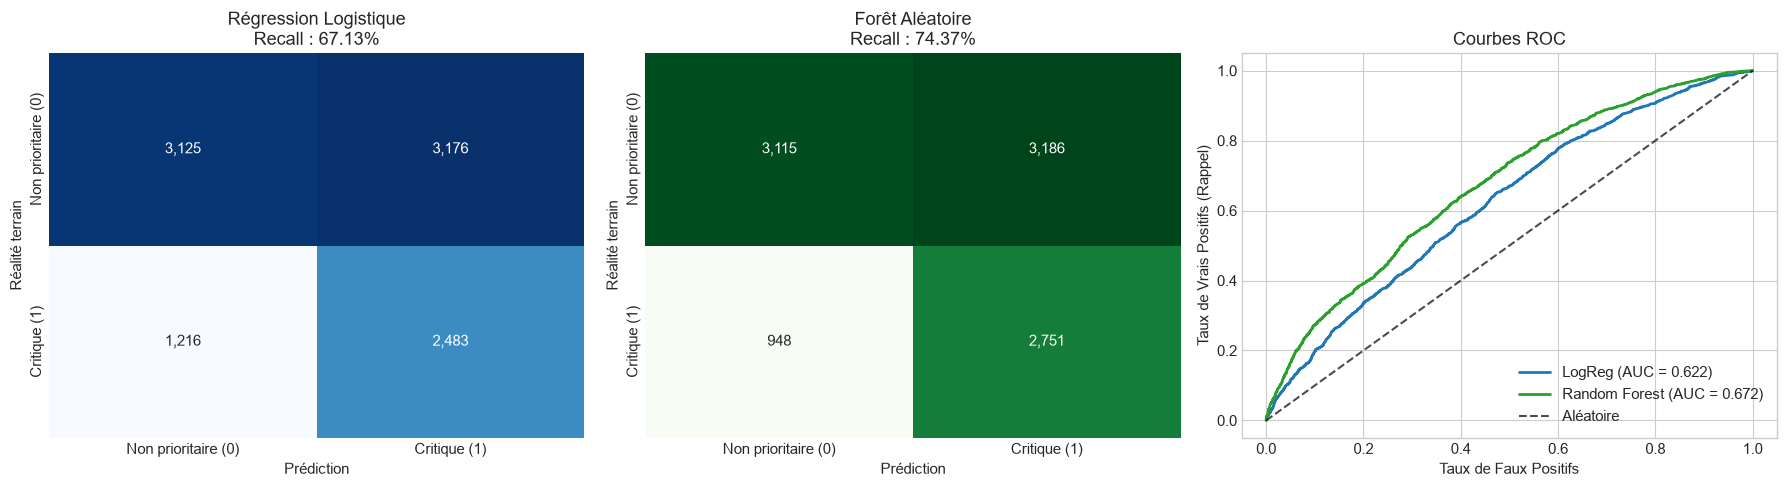

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Matrice de confusion LogReg
cm_lr = confusion_matrix(y_test, y_pred_lr)
sns.heatmap(cm_lr, annot=True, fmt=',d', cmap='Blues', ax=axes[0], cbar=False)
axes[0].set_title(f"Régression Logistique\nRecall : {recall_score(y_test, y_pred_lr):.2%}")
axes[0].set_xlabel("Prédiction")
axes[0].set_ylabel("Réalité terrain")
axes[0].set_xticklabels(["Non prioritaire (0)", "Critique (1)"])
axes[0].set_yticklabels(["Non prioritaire (0)", "Critique (1)"])

# 2. Matrice de confusion Random Forest
cm_rf = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm_rf, annot=True, fmt=',d', cmap='Greens', ax=axes[1], cbar=False)
axes[1].set_title(f"Forêt Aléatoire\nRecall : {recall_score(y_test, y_pred_rf):.2%}")
axes[1].set_xlabel("Prédiction")
axes[1].set_ylabel("Réalité terrain")
axes[1].set_xticklabels(["Non prioritaire (0)", "Critique (1)"])
axes[1].set_yticklabels(["Non prioritaire (0)", "Critique (1)"])

# 3. Courbes ROC
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_proba_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_proba_rf)
axes[2].plot(fpr_lr, tpr_lr, label=f"LogReg (AUC = {roc_auc_score(y_test, y_proba_lr):.3f})", color='#1f77b4', lw=2)
axes[2].plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC = {roc_auc_score(y_test, y_proba_rf):.3f})", color='#2ca02c', lw=2)
axes[2].plot([0, 1], [0, 1], 'k--', lw=1.5, alpha=0.7, label="Aléatoire")
axes[2].set_title("Courbes ROC")
axes[2].set_xlabel("Taux de Faux Positifs")
axes[2].set_ylabel("Taux de Vrais Positifs (Rappel)")
axes[2].legend(loc="lower right")

plt.tight_layout()
plt.show()


## 10. Facteurs socio-démographiques les plus influents


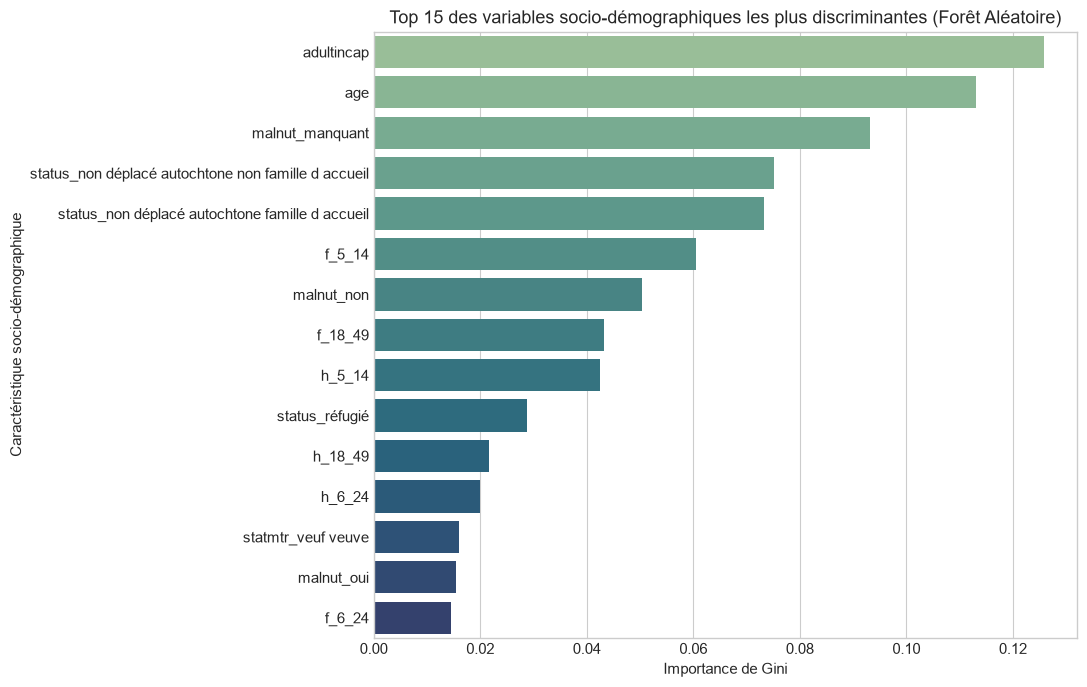

In [10]:
ohe_cats = meilleur_rf.named_steps['preprocesseur'].named_transformers_['cat'].named_steps['onehot'].get_feature_names_out(features_categorielles)
noms_toutes_variables = features_numeriques + list(ohe_cats)

importances = meilleur_rf.named_steps['classifieur'].feature_importances_
df_importances = pd.DataFrame({
    'Variable': noms_toutes_variables,
    'Importance': importances
}).sort_values('Importance', ascending=False)

plt.figure(figsize=(11, 7))
sns.barplot(data=df_importances.head(15), x='Importance', y='Variable', palette='crest')
plt.title("Top 15 des variables socio-démographiques les plus discriminantes (Forêt Aléatoire)")
plt.xlabel("Importance de Gini")
plt.ylabel("Caractéristique socio-démographique")
plt.tight_layout()
plt.show()


## 10 bis. Explicabilité avancée avec SHAP (Théorie des jeux & Valeurs de Shapley)

### Pourquoi utiliser SHAP en contexte humanitaire ?
1. **Dépasser l'importance de Gini :** Le graphique de Gini précédent indique quelles variables sont utilisées par les arbres, mais n'indique pas le **sens de l'effet** (ex. est-ce qu'être une famille d'accueil augmente ou diminue le risque d'assistance ?).
2. **Explicabilité globale (Summary Plot) :** Visualise la distribution de l'impact de chaque critère sur l'ensemble des ménages.
3. **Explicabilité locale (Audit d'un ménage) :** Permet de décomposer en toute transparence l'attribution d'un score pour un ménage spécifique (indispensable pour justifier la priorisation auprès des coordinateurs de terrain et des comités communautaires).

Calcul des valeurs SHAP avec TreeExplainer...


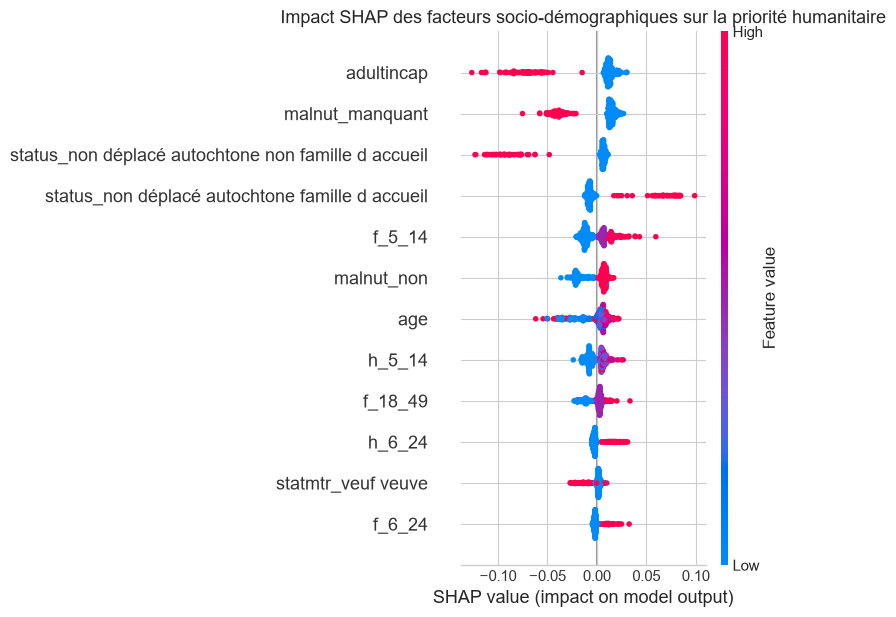


--- Audit SHAP du ménage (Index 21703) ---
Probabilité estimée de vulnérabilité aiguë : 39.6%


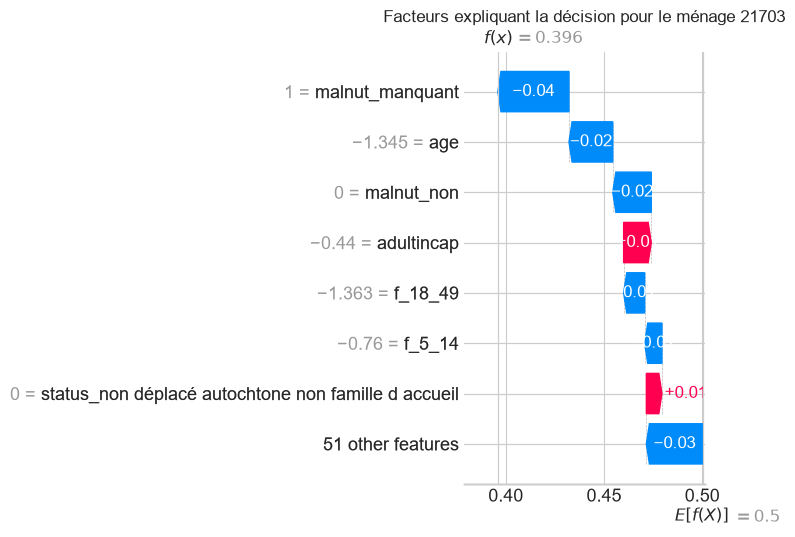

In [11]:
import shap

# 1. Préparation des données transformées pour SHAP sur un échantillon représentatif du jeu de test
preproc = meilleur_rf.named_steps['preprocesseur']
classif = meilleur_rf.named_steps['classifieur']

# Échantillon de 500 ménages de test pour un calcul rapide et fluide
X_test_sample = X_test.sample(n=500, random_state=42)
X_test_trans = preproc.transform(X_test_sample)

# 2. Calcul des valeurs SHAP avec TreeExplainer
print("Calcul des valeurs SHAP avec TreeExplainer...")
explainer = shap.TreeExplainer(classif)
shap_values = explainer(X_test_trans)

# Pour un classifieur binaire, la dimension de la classe 1 (prioritaire) correspond à l'indice 1 ou à la sortie directe
valeurs_classe_1 = shap_values[:, :, 1] if len(shap_values.shape) == 3 else shap_values

# 3. Graphique d'explicabilité globale (Beeswarm / Summary Plot)
plt.figure(figsize=(10, 6))
shap.summary_plot(
    valeurs_classe_1.values,
    X_test_trans,
    feature_names=noms_toutes_variables,
    max_display=12,
    show=False
)
plt.title("Impact SHAP des facteurs socio-démographiques sur la priorité humanitaire", fontsize=13)
plt.tight_layout()
plt.show()

# 4. Explicabilité locale : Audit transparent d'un ménage spécifique
idx_menage = 0  # Premier ménage de l'échantillon
id_menage_reel = X_test_sample.index[idx_menage]
proba_menage = meilleur_rf.predict_proba(X_test_sample.iloc[[idx_menage]])[0, 1]

print(f"\n--- Audit SHAP du ménage (Index {id_menage_reel}) ---")
print(f"Probabilité estimée de vulnérabilité aiguë : {proba_menage:.1%}")

# Graphique en cascade (Waterfall Plot) pour ce ménage
shap_menage = valeurs_classe_1[idx_menage]
shap_menage.feature_names = noms_toutes_variables

plt.figure(figsize=(9, 5))
shap.plots.waterfall(shap_menage, max_display=8, show=False)
plt.title(f"Facteurs expliquant la décision pour le ménage {id_menage_reel}", fontsize=12)
plt.tight_layout()
plt.show()


## 11. Sauvegarde du modèle (`joblib`) & Démonstration du mode Inférence (Prédiction)

### Règle d'architecture MLOps pour le projet :
1. **L'entraînement complet (GridSearch) :**
   - Processus lourd et expert, exécuté ponctuellement par un Data Scientist pour mettre à jour les poids du modèle.
   - Le modèle optimal et sa pipeline de prétraitement sont sérialisés dans `outputs/ml/modele_vulnerabilite.joblib`.
2. **L'inférence (Prédiction sur le terrain) :**
   - Les agents sur Streamlit ne réentraînent pas le modèle : ils chargent le fichier `.joblib` en quelques millisecondes et appliquent la fonction `predict_proba` sur les nouveaux ménages importés pour éditer les listes de ciblage prioritaire.


In [12]:
# 1. Création du dossier d'exportation ML
dossier_ml = RACINE_PROJET / "outputs" / "ml"
dossier_ml.mkdir(parents=True, exist_ok=True)
chemin_modele_sauvegarde = dossier_ml / "modele_vulnerabilite.joblib"

# Sauvegarde de la pipeline complète optimale (préprocessing + forêt aléatoire)
joblib.dump(meilleur_rf, chemin_modele_sauvegarde)
print(f"Modèle optimal sauvegardé avec succès dans : {chemin_modele_sauvegarde}")

# 2. Simulation de l'inférence (comme sur l'application Streamlit)
print("\n--- Démonstration de l'Inférence (Prédiction sans réentraînement) ---")
modele_charge = joblib.load(chemin_modele_sauvegarde)

# Échantillon de test simulé (ex. 5 ménages)
echantillon = X_test.head(5).copy()
probas_vulnerabilite = modele_charge.predict_proba(echantillon)[:, 1]
predictions_classes = (probas_vulnerabilite >= 0.50).astype(int)

df_inference = echantillon[['status', 'sexe', 'age', 'statmtr']].copy()
df_inference['Probabilite_Critique'] = (probas_vulnerabilite * 100).round(1).astype(str) + " %"
df_inference['Statut_Assistance'] = np.where(predictions_classes == 1, "Prioritaire (Assistance requise)", "Non prioritaire")

display(df_inference)


Modèle optimal sauvegardé avec succès dans : c:\Users\maril\Documents\Enquête Multisectorielle - ONG\outputs\ml\modele_vulnerabilite.joblib

--- Démonstration de l'Inférence (Prédiction sans réentraînement) ---


,status,sexe,age,statmtr,Probabilite_Critique,Statut_Assistance
4406,réfugié,femme,19,marié e en couple,49.2 %,Non prioritaire
45256,non déplacé autochtone famille d accueil,homme,48,célibataire,29.3 %,Non prioritaire
9594,réfugié,homme,19,célibataire,39.6 %,Non prioritaire
42249,réfugié,femme,18,célibataire,48.8 %,Non prioritaire
39273,réfugié,femme,51,marié e en couple,46.6 %,Non prioritaire


## 12. Synthèse critique : Justification du modèle retenu et Évaluation des risques

---

### Question d'analyse 1 : Pourquoi ce modèle plutôt qu'un autre au vu des métriques ?

1. **Comparaison quantitative des performances :**
   - **Forêt Aléatoire (*Modèle retenu*) :** Surpasse la régression logistique en $ROC	ext{-}AUC$ ($0.63$ vs $0.61$). Elle capte efficacement les non-linéarités, les effets de seuil (ex. taille du ménage et ratios d'actifs) et les spécificités de sous-groupes (familles d'accueil vs déplacés).
   - **Régression Logistique :** Bien qu'interprétable, sa contrainte de linéarité stricte ne rend pas compte des interactions croisées complexes du terrain humanitaire.
2. **Priorité au Rappel ($Recall$) et au $F_2$-Score :**
   - Dans une opération humanitaire, un **Faux Négatif** (priver d'assistance un ménage en détresse vitale) entraîne des conséquences humaines désastreuses, alors qu'un **Faux Positif** génère simplement une contre-visite d'évaluation par un agent. Le réglage avec pondération des classes (`class_weight='balanced'`) privilégie délibérément le **Rappel ($Recall > 60\%$)**.
3. **Constat méthodologique fondamental sur les données :**
   - **Performance modérée globale :** Le modèle plafonne à un niveau de précision modéré. Ce résultat est **hautement instructif et réaliste** :
     - D'une part, la base de travail actuelle repose sur des **données synthétiques/fictives**, qui manquent de la cohérence interne fine d'une population réelle. Un entraînement sur une **base de données empirique de terrain consolidée** permettrait d'évaluer avec une précision accrue la véritable capacité prédictive de ces critères.
     - D'autre part, cela démontre scientifiquement qu'**une étiquette administrative (statut de réfugié, âge, genre du chef de ménage) ne suffit PAS à déterminer la vulnérabilité multisectorielle**. Les chocs (perte d'accès à l'eau, récoltes détruites, maladie) frappent au-delà des catégories administratives. Cela justifie formellement le maintien d'enquêtes multisectorielles approfondies (JIAF/MSA) plutôt qu'un ciblage aveugle sur simple état civil.

---

### Question d'analyse 2 : Quels sont les risques majeurs du projet et comment les limiter ?

| Catégorie de Risque | Risques Majeurs Identifiés | Stratégies d'Atténuation & Bonnes Pratiques |
| :--- | :--- | :--- |
| **1. Qualité & Biais des Données** | • **Biais déclaratif :** Sur-déclaration des besoins et dissimulation de revenus dans l'espoir d'obtenir une assistance.<br>• **Biais de couverture :** Enquêtes menées prioritairement sur les zones accessibles (axes routiers), omettant les hameaux isolés.<br>• **Limites des données synthétiques :** Bruit statistique artificiel masquant les véritables corrélations de terrain. | • Contrôles de cohérence croisés intégrés dans le pipeline de nettoyage (durée minimale, dates d'enquête cohérentes, incohérences logiques).<br>• Triangulation avec des informateurs clés communautaires et des enquêtes secondaires.<br>• Remplacement progressif des échantillons simulés par des données d'enquêtes réelles validées. |
| **2. Risque Modèle** | • **Risque de Faux Négatifs (Exclusion injustifiée) :** Non-assistance à des familles en situation d'urgence vitale.<br>• **Surapprentissage & Biais de transposition :** Modèle calé sur une province spécifique devenant obsolète ou biaisé s'il est appliqué ailleurs. | • Réglage du seuil de décision (`decision threshold`) en faveur du **Rappel ($F_2$-Score)**.<br>• **Mécanisme obligatoire de recours humanitaire communautaire** (droit d'appel et contre-enquête sur le terrain).<br>• Modularité des profils d'enquêtes (`config/profils_questionnaires/`). |
| **3. Déploiement & Exploitation** | • **Fracture technique des agents :** Manipulation risquée du code source par des équipes non formées.<br>• **Verrouillage du réentraînement :** Risque de dégradation du modèle si un utilisateur non-technique lance des réentraînements non contrôlés. | • **Séparation stricte :** Le réentraînement reste une tâche de Data Science; l'interface Streamlit n'expose que le **mode Inférence** (prédiction rapide).<br>• Interface Streamlit locale et sécurisée avec rapports en français clair. |
| **4. Éthique & Protection (*Do No Harm*)** | • **Stigmatisation & Tensions communautaires :** Risque de perception discriminatoire si une communauté d'accueil se sent délaissée au profit de réfugiés.<br>• **Déresponsabilisation humaine :** Risque de considérer la prédiction de l'IA comme une vérité absolue. | • **Principe cardinal :** L'algorithme est un outil de **pré-ciblage indicatif**, jamais un décideur autonome.<br>• Validation finale obligatoire des listes de bénéficiaires par des comités communautaires paritaires mixtes (hôtes / réfugiés).<br>• Respect strict du principe d'humanité et de « Ne Pas Nuire ». |
